# Lecture 3: Kernel Density Estimation, Interpolation & Linear Least-Squares Fitting

Introduce the main computational concepts and develop the mathematical foundations of the numerical methods, explaining how they are derived and the ideas behind them.

## **Part A — Theory and Numerical Methods**


# 📚 Theory from `notes_scicom`: Distribution estimation and fitting

## 4. Distribution estimation

The aim is to estimate an entire PDF, not only the first moments, from a collection of data points.

### 4.1 Estimation from a histogram

Divide the data range into bins $B_m$ of fixed width $h$:
$$
x_1+hm\le x<x_1+h(m+1),
\qquad m\in\{0,\ldots,M-1\},
$$
where $x_1=\min(x)$. If $\nu_m$ is the number of observations in bin $B_m$, then
$$
\Pr(x\in B_m)=\frac{\nu_m}{n}.
$$
The corresponding PDF estimate is
$$
\widehat f_X(x)=\frac{\nu_m}{nh},
\qquad x\in B_m.
$$
For a fixed number of data points there is an optimal bin size $h_{\mathrm{opt}}$: very small bins overfit the data, while very large bins hide structure.

### 4.2 Estimation from the cumulative distribution function

To estimate a distribution, binning is not necessary. For each $x$, count the number $M(x)$ of data points $x_k$ satisfying $x_k<x$. The empirical CDF is
$$
\widehat F_X(x)=\frac{M(x)}{n}.
$$
It has a step of size $1/n$ at each observation. If the observations are sorted as $\widetilde{x}_j$, then
$$
\widehat F_X(\widetilde{x}_j)=\frac{j}{n}.
$$
Compared with a histogram, this method requires no bin-size parameter, permits verification with a Kolmogorov--Smirnov test, and allows direct visual inspection in simple cases.

### 4.3 Kernel density estimator

To smooth the approximation of a PDF, use a kernel function $K$ satisfying
$$
\int K(x)\,dx=1,
\qquad K(x)\ge0.
$$
For independent observations $x_1,\ldots,x_n$, the kernel density estimator is
$$
\widehat f_h(x)=\frac1n\sum_{i=1}^{n}K_h(x-x_i)
=\frac{1}{nh}\sum_{i=1}^{n}K\left(\frac{x-x_i}{h}\right),
$$
where $h>0$ is the bandwidth. Each data point contributes a local PDF
$$
\frac1hK\left(\frac{x-x_i}{h}\right),
$$
which is usually largest at $x_i$. The final estimate is a linear combination of these local PDFs, so regions containing more data points have higher estimated density. The bandwidth controls the balance between a noisy estimate and an over-smoothed estimate.

## 5. Fitting methods

The aim of fitting methods is to create a function based on data. There are two approaches:

1. **Interpolation:** connect all data points by combining multiple functions.
2. **Curve fitting:** capture the trend of the data with one function over the whole range; the function does not have to pass through every point.

### 5.1 Curve fitting and mean-square error

Suppose there are $n$ points $(x_i,y_i)$ and the observations have typical standard deviations $\sigma_i$. A fitting function should assign the same value to positive and negative errors and should weight larger errors more heavily. This is done by minimizing a squared error such as the mean-square error:
$$
\mathrm{MSE}=\frac1n\sum_{i=1}^{n}(y_i-\widehat y_i)^2,
$$
where $y_i$ is the observed value and $\widehat y_i$ the predicted value.

### 5.2 Interpolation and weighted least squares

Write the proposed function as a linear combination of basis functions:
$$
y(x)=\sum_{j=1}^{M}A_j f_j(x).
$$
The coefficients $A_j$ are chosen to fit all the data points. If the uncertainties are known, minimize the weighted mean-square error
$$
\mathrm{MSE}(A_1,\ldots,A_M)
=\frac1n\sum_{i=1}^{n}\frac{1}{\sigma_i^2}
\left(y_i-\sum_{j=1}^{M}A_jf_j(x_i)\right)^2.
$$
Setting the derivatives with respect to the coefficients equal to zero gives a linear system
$$
\alpha A=\beta,
$$
with
$$
\alpha_{mj}=\sum_{i=1}^{n}\frac{f_j(x_i)f_m(x_i)}{\sigma_i^2},
\qquad
\beta_m=\sum_{i=1}^{n}\frac{y_i f_m(x_i)}{\sigma_i^2}.
$$
The coefficients can be found when the matrix $\alpha$ is non-degenerate. For polynomial fitting, choose $f_j(x)=x^j$; then
$$
P_M(x)=a_0+a_1x+a_2x^2+\cdots+a_Mx^M.
$$
For $M=1$, this is linear regression, $f(x)=a_0+a_1x=b+ax$.

The notebook examples apply these ideas to KDE, interpolation, and least-squares fitting. Interpolation is appropriate when the values are trusted and should be matched exactly; fitting is preferable when measurements contain noise and the goal is to recover an underlying trend.


## **Part B — Guided Implementation**


In the previous chapter we covered Gaussian mixture models, which are a kind of hybrid between a clustering estimator and a density estimator.
Recall that a density estimator is an algorithm that takes a $D$-dimensional dataset and produces an estimate of the $D$-dimensional probability distribution that data is drawn from.
The GMM algorithm accomplishes this by representing the density as a weighted sum of Gaussian distributions.
*Kernel density estimation* (KDE) is in some senses an algorithm that takes the mixture-of-Gaussians idea to its logical extreme: it uses a mixture consisting of one Gaussian component *per point*, resulting in an essentially nonparametric estimator of density.
In this chapter, we will explore the motivation and uses of KDE.

We begin with the standard imports:

# In Depth: Kernel Density Estimation

In [30]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

## Motivating Kernel Density Estimation: Histograms

As mentioned previously, a density estimator is an algorithm that seeks to model the probability distribution that generated a dataset.
For one-dimensional data, you are probably already familiar with one simple density estimator: the histogram.
A histogram divides the data into discrete bins, counts the number of points that fall in each bin, and then visualizes the results in an intuitive manner.

For example, let's create some data that is drawn from two normal distributions:

In [31]:
def make_data(N, f=0.3, rseed=1):
    rand = np.random.RandomState(rseed)
    x = rand.randn(N)
    x[int(f * N):] += 5
    return x

x = make_data(1000)

We have previously seen that the standard count-based histogram can be created with the `plt.hist` function.
By specifying the `density` parameter of the histogram, we end up with a normalized histogram where the height of the bins does not reflect counts, but instead reflects probability density (see the following figure):

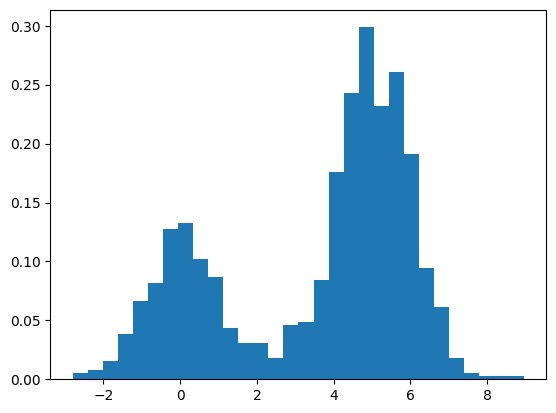

In [32]:
hist = plt.hist(x, bins=30, density=True)

Notice that for equal binning, this normalization simply changes the scale on the y-axis, leaving the relative heights essentially the same as in a histogram built from counts.
This normalization is chosen so that the total area under the histogram is equal to 1, as we can confirm by looking at the output of the histogram function:

In [33]:
density, bins, patches = hist
widths = bins[1:] - bins[:-1]
(density * widths).sum()

np.float64(1.0)

One of the issues with using a histogram as a density estimator is that the choice of bin size and location can lead to representations that have qualitatively different features.
For example, if we look at a version of this data with only 20 points, the choice of how to draw the bins can lead to an entirely different interpretation of the data!
Consider this example, visualized in the following figure:

In [34]:
x = make_data(20)
bins = np.linspace(-5, 10, 10)

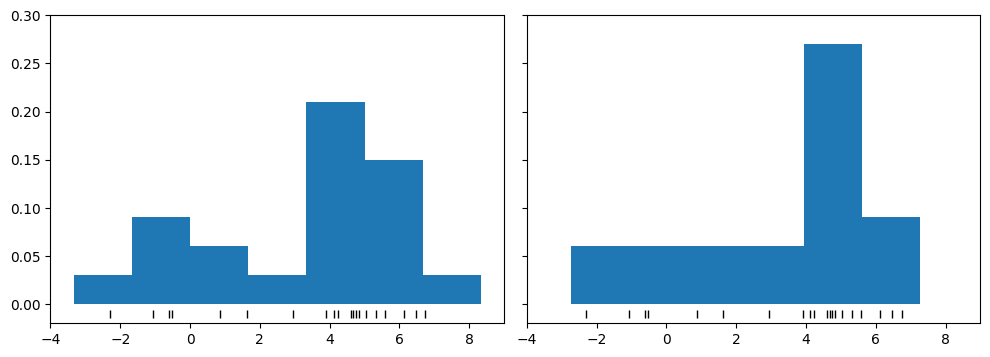

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4),
                       sharex=True, sharey=True,
                       subplot_kw={'xlim':(-4, 9),
                                   'ylim':(-0.02, 0.3)})
fig.subplots_adjust(wspace=0.05)
for i, offset in enumerate([0.0, 0.6]):
    ax[i].hist(x, bins=bins + offset, density=True)
    ax[i].plot(x, np.full_like(x, -0.01), '|k',
               markeredgewidth=1)

On the left, the histogram makes clear that this is a bimodal distribution.
On the right, we see a unimodal distribution with a long tail.
Without seeing the preceding code, you would probably not guess that these two histograms were built from the same data. With that in mind, how can you trust the intuition that histograms confer?
And how might we improve on this?

Stepping back, we can think of a histogram as a stack of blocks, where we stack one block within each bin on top of each point in the dataset.
Let's view this directly (see the following figure):

(-0.2, 8.0)

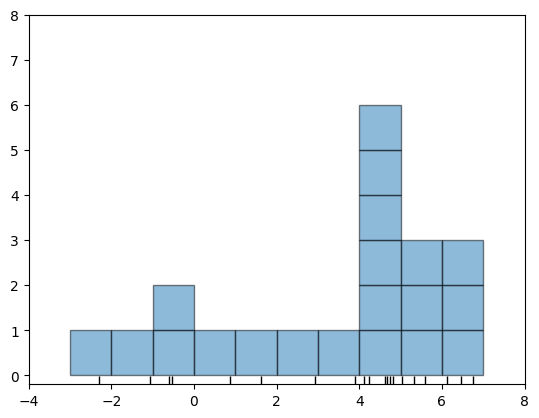

In [36]:
fig, ax = plt.subplots()
bins = np.arange(-3, 8)
ax.plot(x, np.full_like(x, -0.1), '|k',
        markeredgewidth=1)
for count, edge in zip(*np.histogram(x, bins)):
    for i in range(count):
        ax.add_patch(plt.Rectangle(
            (edge, i), 1, 1, ec='black', alpha=0.5))
ax.set_xlim(-4, 8)
ax.set_ylim(-0.2, 8)

The problem with our two binnings stems from the fact that the height of the block stack often reflects not the actual density of points nearby, but coincidences of how the bins align with the data points.
This misalignment between points and their blocks is a potential cause of the poor histogram results seen here.
But what if, instead of stacking the blocks aligned with the *bins*, we were to stack the blocks aligned with the *points they represent*?
If we do this, the blocks won't be aligned, but we can add their contributions at each location along the x-axis to find the result.
Let's try this (see the following figure):

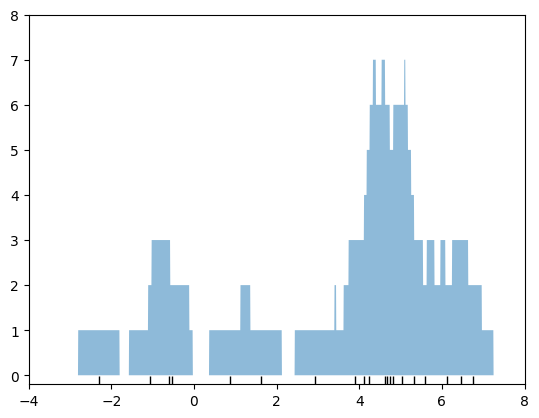

In [37]:
x_d = np.linspace(-4, 8, 2000)
density = sum((abs(xi - x_d) < 0.5) for xi in x)

plt.fill_between(x_d, density, alpha=0.5)
plt.plot(x, np.full_like(x, -0.1), '|k', markeredgewidth=1)

plt.axis([-4, 8, -0.2, 8]);

The result looks a bit messy, but it's a much more robust reflection of the actual data characteristics than is the standard histogram.
Still, the rough edges are not aesthetically pleasing, nor are they reflective of any true properties of the data.
In order to smooth them out, we might decide to replace the blocks at each location with a smooth function, like a Gaussian.
Let's use a standard normal curve at each point instead of a block (see the following figure):

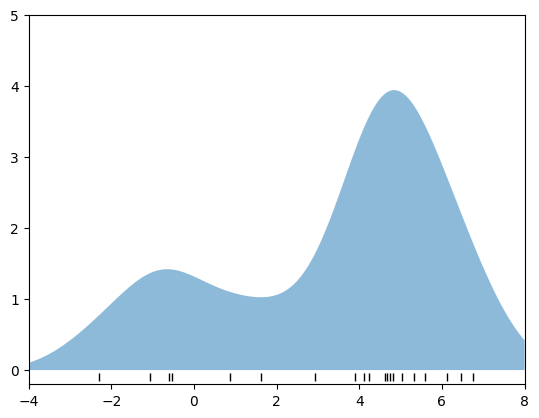

In [38]:
from scipy.stats import norm
x_d = np.linspace(-4, 8, 1000)
density = sum(norm(xi).pdf(x_d) for xi in x)

plt.fill_between(x_d, density, alpha=0.5)
plt.plot(x, np.full_like(x, -0.1), '|k', markeredgewidth=1)

plt.axis([-4, 8, -0.2, 5]);

This smoothed-out plot, with a Gaussian distribution contributed at the location of each input point, gives a much more accurate idea of the shape of the data distribution, and one that has much less variance (i.e., changes much less in response to differences in sampling).

What we've landed on in the last two plots is what's called kernel density estimation in one dimension: we have placed a "kernel"—a square or "tophat"-shaped kernel in the former, a Gaussian kernel in the latter—at the location of each point, and used their sum as an estimate of density.
With this intuition in mind, we'll now explore kernel density estimation in more detail.

## Kernel Density Estimation in Practice

The free parameters of kernel density estimation are the *kernel*, which specifies the shape of the distribution placed at each point, and the *kernel bandwidth*, which controls the size of the kernel at each point.
In practice, there are many kernels you might use for kernel density estimation: in particular, the Scikit-Learn KDE implementation supports six kernels, which you can read about in the ["Density Estimation" section](http://scikit-learn.org/stable/modules/density.html) of the documentation.

While there are several versions of KDE implemented in Python (notably in the SciPy and `statsmodels` packages), I prefer to use Scikit-Learn's version because of its efficiency and flexibility.
It is implemented in the `sklearn.neighbors.KernelDensity` estimator, which handles KDE in multiple dimensions with one of six kernels and one of a couple dozen distance metrics.
Because KDE can be fairly computationally intensive, the Scikit-Learn estimator uses a tree-based algorithm under the hood and can trade off computation time for accuracy using the `atol` (absolute tolerance) and `rtol` (relative tolerance) parameters.
The kernel bandwidth can be determined using Scikit-Learn's standard cross-validation tools, as we will soon see.

Let's first show a simple example of replicating the previous plot using the Scikit-Learn `KernelDensity` estimator (see the following figure):

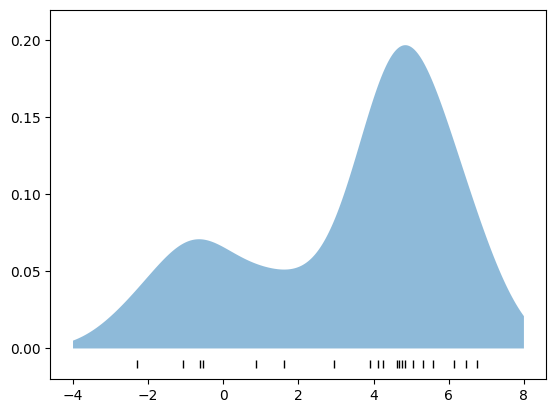

In [39]:
from sklearn.neighbors import KernelDensity

# instantiate and fit the KDE model
kde = KernelDensity(bandwidth=1.0, kernel='gaussian')
kde.fit(x[:, None])

# score_samples returns the log of the probability density
logprob = kde.score_samples(x_d[:, None])

plt.fill_between(x_d, np.exp(logprob), alpha=0.5)
plt.plot(x, np.full_like(x, -0.01), '|k', markeredgewidth=1)
plt.ylim(-0.02, 0.22);

The result here is normalized such that the area under the curve is equal to 1.

## Selecting the Bandwidth via Cross-Validation

The final estimate produced by a KDE procedure can be quite sensitive to the choice of bandwidth, which is the knob that controls the bias–variance trade-off in the estimate of density.
Too narrow a bandwidth leads to a high-variance estimate (i.e., overfitting), where the presence or absence of a single point makes a large difference. Too wide a bandwidth leads to a high-bias estimate (i.e., underfitting), where the structure in the data is washed out by the wide kernel.

There is a long history in statistics of methods to quickly estimate the best bandwidth based on rather stringent assumptions about the data: if you look up the KDE implementations in the SciPy and `statsmodels` packages, for example, you will see implementations based on some of these rules.

In machine learning contexts, we've seen that such hyperparameter tuning often is done empirically via a cross-validation approach.
With this in mind, Scikit-Learn's `KernelDensity` estimator is designed such that it can be used directly within the package's standard grid search tools.
Here we will use `GridSearchCV` to optimize the bandwidth for the preceding dataset.
Because we are looking at such a small dataset, we will use leave-one-out cross-validation, which minimizes the reduction in training set size for each cross-validation trial:

In [40]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import LeaveOneOut

bandwidths = 10 ** np.linspace(-1, 1, 100)
grid = GridSearchCV(KernelDensity(kernel='gaussian'),
                    {'bandwidth': bandwidths},
                    cv=LeaveOneOut())
grid.fit(x[:, None]);

Now we can find the choice of bandwidth that maximizes the score (which in this case defaults to the log-likelihood):

In [41]:
grid.best_params_

{'bandwidth': np.float64(1.1233240329780276)}

The optimal bandwidth happens to be very close to what we used in the example plot earlier, where the bandwidth was 1.0 (i.e., the default width of `scipy.stats.norm`).

One benefit of such a generative classifier is interpretability of results: for each unknown sample, we not only get a probabilistic classification, but a *full model* of the distribution of points we are comparing it to!
If desired, this offers an intuitive window into the reasons for a particular classification that algorithms like SVMs and random forests tend to obscure.

If you would like to take this further, here are some ideas for improvements that could be made to our KDE classifier model:

- You could allow the bandwidth in each class to vary independently.
- You could optimize these bandwidths not based on their prediction score, but on the likelihood of the training data under the generative model within each class (i.e. use the scores from `KernelDensity` itself rather than the global prediction accuracy).

Finally, if you want some practice building your own estimator, you might tackle building a similar Bayesian classifier using Gaussian mixture models instead of KDE.

## 1. Interpolation & Linear Least-Squares Fitting

## Experimental Data Analysis

Every physics experiment produces a finite set of noisy, discrete measurements $(x_i, y_i)$. Turning that
table of numbers into physical understanding requires answering one of two very different questions:

1. **"What is the value between my measurements?"** — you trust the data points exactly, and you want a
   smooth curve that passes through every one of them. This is **interpolation**.
2. **"What is the underlying physical law, and what are its parameters?"** — you know (or suspect) the
   *noise* is real, and you want the smooth model that best explains the *trend*, not a curve that chases
   every wiggle. This is **curve fitting**.

This lecture builds both skills using only `numpy` and `scipy` (every fit
here is done with the same linear-algebra machinery you already used to solve circuits in
`3.CoupledSystems`).

### Interpolation

### The temptation: fit one big polynomial through everything

If you have $n+1$ data points, you can *always* find a degree-$n$ polynomial that passes through every one
of them exactly (this is the same "one polynomial to hit every point" idea behind fitting a parabola through
3 points, extended to more points and points). It sounds like the natural thing to do. It is usually a
terrible idea.

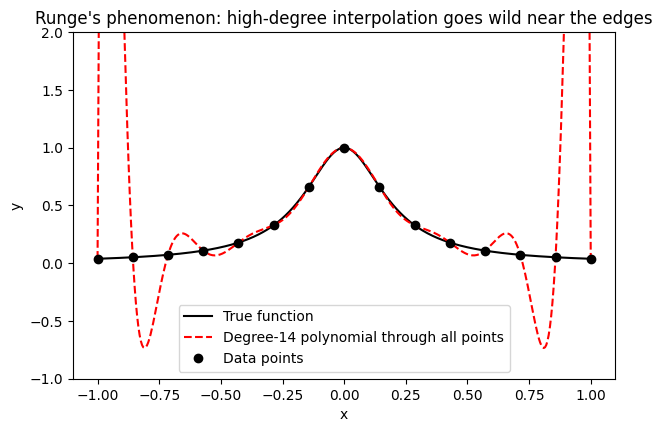

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline

# A smooth, well-behaved function...
def f_true(x):
    return 1.0 / (1.0 + 25 * x**2)   # Runge's function

x_nodes = np.linspace(-1, 1, 15)
y_nodes = f_true(x_nodes)

# ...fit a single degree-14 polynomial through all 15 points
coeffs = np.polyfit(x_nodes, y_nodes, deg=14)
poly_interp = np.poly1d(coeffs)

x_dense = np.linspace(-1, 1, 400)

plt.figure(figsize=(7, 4.5))
plt.plot(x_dense, f_true(x_dense), 'k-', label='True function')
plt.plot(x_dense, poly_interp(x_dense), 'r--', label='Degree-14 polynomial through all points')
plt.plot(x_nodes, y_nodes, 'o', color='k', label='Data points')
plt.ylim(-1, 2)
plt.xlabel('x'); plt.ylabel('y')
plt.title("Runge's phenomenon: high-degree interpolation goes wild near the edges")
plt.legend()
plt.show()


This is **Runge's phenomenon**: a single high-degree polynomial forced through many points develops huge,
unphysical oscillations, especially near the edges of the data — even though every individual point is fit
*exactly*. The image below shows the same effect on a different function, with the wiggles clearly visible
between the (exactly-interpolated) data points.

The fix is to give up on a *single* polynomial and instead use many *low-degree* polynomial pieces, one
between each pair of neighboring points, and stitch them together smoothly. This is a **spline**.

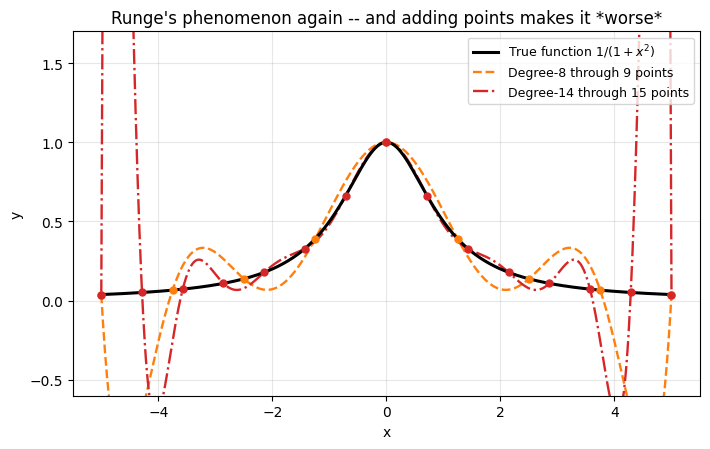

In [43]:
# The same effect on a different function, on a wider interval. Both curves
# below pass *exactly* through their own data points -- these are genuine
# interpolants, not least-squares fits.
def f_lorentz(x):
    return 1.0 / (1.0 + x**2)

x_dense_L = np.linspace(-5, 5, 600)

plt.figure(figsize=(7.2, 4.6))
plt.plot(x_dense_L, f_lorentz(x_dense_L), 'k-', lw=2.2,
         label='True function $1/(1+x^2)$', zorder=5)
for n_nodes, style, col in [(9, '--', 'tab:orange'), (15, '-.', 'tab:red')]:
    xn = np.linspace(-5, 5, n_nodes)
    poly = np.poly1d(np.polyfit(xn, f_lorentz(xn), n_nodes - 1))
    plt.plot(x_dense_L, poly(x_dense_L), style, color=col, lw=1.7,
             label=f'Degree-{n_nodes - 1} through {n_nodes} points')
    plt.plot(xn, f_lorentz(xn), 'o', color=col, ms=5, zorder=6)

plt.ylim(-0.6, 1.7); plt.xlabel('x'); plt.ylabel('y')
plt.title("Runge's phenomenon again -- and adding points makes it *worse*")
plt.legend(fontsize=9, loc='upper right'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Splines: piecewise polynomials, stitched smoothly

A cubic spline $S(x)$ is built from a cubic polynomial $S_i(x) = a_i + b_i(x-x_i) + c_i(x-x_i)^2 + d_i(x-x_i)^3$
on each interval $[x_i, x_{i+1}]$, with the pieces required to:

1. **Match the data**: $S_i(x_i) = y_i$ for every node.
2. **Join smoothly**: the value, first derivative, *and* second derivative of neighboring pieces agree at
   each shared node (no kinks, no sudden change in curvature).

Condition (2) is what makes a spline different from just drawing $n$ independent parabolas — physically, if
your data represents something like a particle's smooth trajectory, you *want* the interpolant's velocity and
acceleration to be continuous too, not just its position.

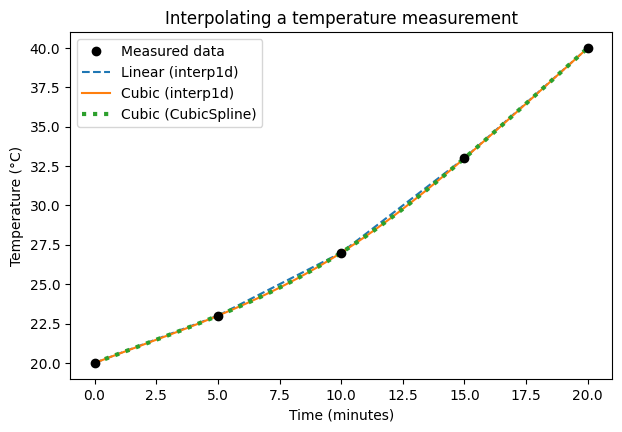

In [44]:
time = np.array([0, 5, 10, 15, 20])
temperature = np.array([20, 23, 27, 33, 40])

f_linear = interp1d(time, temperature, kind='linear')
f_cubic = interp1d(time, temperature, kind='cubic')
cs = CubicSpline(time, temperature)

time_dense = np.linspace(0, 20, 200)

plt.figure(figsize=(7, 4.5))
plt.plot(time, temperature, 'ko', label='Measured data', zorder=5)
plt.plot(time_dense, f_linear(time_dense), '--', label='Linear (interp1d)')
plt.plot(time_dense, f_cubic(time_dense), '-', label='Cubic (interp1d)')
plt.plot(time_dense, cs(time_dense), ':', label='Cubic (CubicSpline)', linewidth=3)
plt.xlabel('Time (minutes)'); plt.ylabel('Temperature (°C)')
plt.title('Interpolating a temperature measurement')
plt.legend()
plt.show()


`scipy.interpolate.interp1d(x, y, kind=...)` and `scipy.interpolate.CubicSpline(x, y)` both return a
**callable** — an actual Python function you can evaluate at any new `x` value inside the original range.
`interp1d` supports `kind='linear'`, `'nearest'`, `'quadratic'`, `'cubic'`, among others; `CubicSpline` is a
dedicated, slightly more modern cubic-spline implementation with the same idea. Both agree closely above,
as they should — they're solving the same well-posed problem.

### ⚛️ Physics Application: recovering a force from a tabulated potential

Suppose a simulation or an experiment hands you the potential energy $U(x)$ of a particle only at a handful
of separations — not as a formula, but as a table (this is exactly how tabulated interatomic potentials are
often distributed in molecular dynamics). You need the **force**, $F(x) = -\dfrac{dU}{dx}$, at *arbitrary*
$x$, not just at the tabulated points.

The strategy: interpolate $U(x)$ with a cubic spline to get a smooth, differentiable stand-in for the
potential, then apply the central-difference numerical derivative from `2.Kinematics` to that spline (or use
its built-in derivative). We'll check the result against a Morse potential, whose force we *do* know in
closed form, so we can judge the interpolation's accuracy honestly.

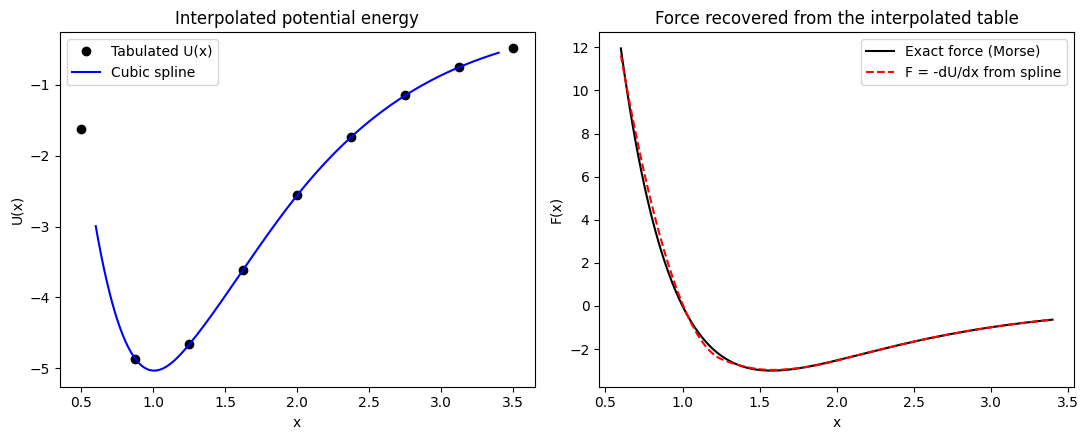

Max force error from only 9 tabulated points: 0.5833


In [45]:
def morse_potential(x, De=5.0, a=1.2, xe=1.0):
    return De * (1 - np.exp(-a * (x - xe)))**2 - De

def morse_force_exact(x, De=5.0, a=1.2, xe=1.0):
    # F = -dU/dx, computed analytically for comparison
    return -2 * De * a * (1 - np.exp(-a * (x - xe))) * np.exp(-a * (x - xe))

# Only a sparse table of (x, U) is "measured"
x_table = np.linspace(0.5, 3.5, 9)
U_table = morse_potential(x_table)

U_spline = CubicSpline(x_table, U_table)

x_fine = np.linspace(0.6, 3.4, 300)
# Differentiate the spline analytically (CubicSpline objects support this directly)
F_from_spline = -U_spline(x_fine, 1)     # 1st derivative of the spline, negated
F_exact = morse_force_exact(x_fine)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(x_table, U_table, 'ko', label='Tabulated U(x)')
axes[0].plot(x_fine, U_spline(x_fine), 'b-', label='Cubic spline')
axes[0].set_xlabel('x'); axes[0].set_ylabel('U(x)'); axes[0].legend()
axes[0].set_title('Interpolated potential energy')

axes[1].plot(x_fine, F_exact, 'k-', label='Exact force (Morse)')
axes[1].plot(x_fine, F_from_spline, 'r--', label='F = -dU/dx from spline')
axes[1].set_xlabel('x'); axes[1].set_ylabel('F(x)'); axes[1].legend()
axes[1].set_title('Force recovered from the interpolated table')
plt.tight_layout()
plt.show()

max_err = np.max(np.abs(F_from_spline - F_exact))
print(f"Max force error from only {len(x_table)} tabulated points: {max_err:.4f}")


Only 9 tabulated energies were enough to recover the force curve to good accuracy — this is the everyday
payoff of interpolation in computational physics: it lets you work with *sparse, expensive-to-generate* data
(experimental measurements, or an expensive quantum-chemistry calculation) as if you had a smooth function you
could evaluate and differentiate anywhere. The single worst point is near the left edge of the table, not in
the interior — the same boundary effect you saw with `np.gradient` in `6.ElectricAndMagneticFields`: a spline
(like a finite difference) has less neighboring information to work with near the ends of the data, so its
derivative is least trustworthy there. Away from the boundary, the error is many times smaller.

### Curve Fitting

Interpolation was built on trusting every data point exactly. Real experimental data is noisy — trusting it
exactly is exactly the wrong thing to do. Watch what happens if we interpolate noisy data instead of fitting
it.

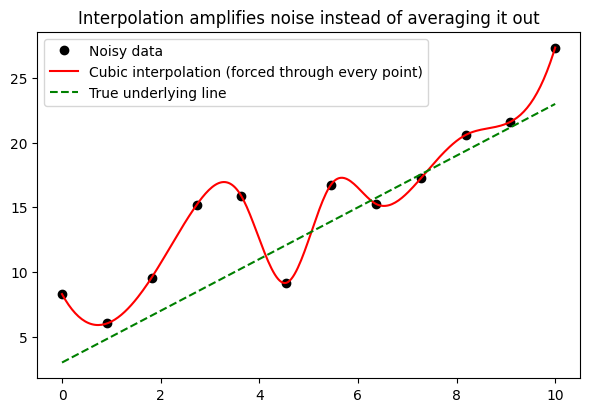

In [46]:
np.random.seed(0)
x_noisy = np.linspace(0, 10, 12)
y_noisy = 2.0 * x_noisy + 3.0 + np.random.normal(scale=3.0, size=len(x_noisy))

f_noisy_cubic = interp1d(x_noisy, y_noisy, kind='cubic')
x_fine = np.linspace(0, 10, 300)

plt.figure(figsize=(7, 4.5))
plt.plot(x_noisy, y_noisy, 'ko', label='Noisy data')
plt.plot(x_fine, f_noisy_cubic(x_fine), 'r-', label='Cubic interpolation (forced through every point)')
plt.plot(x_fine, 2.0 * x_fine + 3.0, 'g--', label='True underlying line')
plt.legend()
plt.title('Interpolation amplifies noise instead of averaging it out')
plt.show()


The interpolant chases every noisy wiggle, producing a curve that is *worse* than a straight line at
representing the true underlying trend. What we want instead is a **model** — a physically motivated
functional form with a handful of free parameters — and the *best* choice of those parameters, in the sense
of minimizing the total mismatch with the data. That is curve fitting.

### Least-squares: minimizing the total squared residual

For a model $y = g(x; \mathbf{p})$ with parameters $\mathbf{p}$, the **residual** at point $i$ is
$r_i = y_i - g(x_i;\mathbf{p})$. Least-squares fitting chooses $\mathbf{p}$ to minimize the sum of squared
residuals,
$$
S(\mathbf{p}) = \sum_{i=1}^N r_i^2 = \sum_{i=1}^N \big(y_i - g(x_i;\mathbf{p})\big)^2 .
$$
Squaring the residuals (rather than, say, summing $|r_i|$) makes $S$ smooth and differentiable, and it
penalizes large deviations more than small ones — a single bad point costs you more than several tiny ones,
which is usually the physically sensible tradeoff for Gaussian-distributed measurement noise.

#### Deriving the straight-line fit

Take the simplest model, $g(x) = mx + b$. Then
$$
S(m,b) = \sum_{i=1}^N \big(y_i - m x_i - b\big)^2 .
$$
At the minimum, both partial derivatives vanish:
$$
\frac{\partial S}{\partial m} = -2\sum_i x_i(y_i - mx_i - b) = 0, \qquad
\frac{\partial S}{\partial b} = -2\sum_i (y_i - mx_i - b) = 0 .
$$
These are two *linear* equations in the two unknowns $m, b$ (this is the key fact we'll generalize below).
Solving them gives the familiar formulas
$$
m = \frac{N\sum x_iy_i - \sum x_i \sum y_i}{N\sum x_i^2 - \left(\sum x_i\right)^2}, \qquad
b = \frac{\sum y_i - m\sum x_i}{N}.
$$

### Generalizing: the same idea with three parameters

The straight-line case had two parameters ($m,b$) and two equations. What happens with three? Take a
quadratic model, $g(x) = c_1 + c_2 x + c_3 x^2$, and follow the *exact same recipe*: write the sum of squared
residuals,
$$
S(c_1,c_2,c_3) = \sum_{i=1}^N \big(y_i - c_1 - c_2 x_i - c_3 x_i^2\big)^2 ,
$$
and set each partial derivative to zero:
$$
\frac{\partial S}{\partial c_1} = -2\sum_i \big(y_i - c_1 - c_2x_i - c_3x_i^2\big) = 0,
$$
$$
\frac{\partial S}{\partial c_2} = -2\sum_i x_i\big(y_i - c_1 - c_2x_i - c_3x_i^2\big) = 0,
$$
$$
\frac{\partial S}{\partial c_3} = -2\sum_i x_i^2\big(y_i - c_1 - c_2x_i - c_3x_i^2\big) = 0.
$$
Nothing conceptually new happened — just more bookkeeping: we now have **three** linear equations in the
**three** unknowns $c_1,c_2,c_3$, and each one is built the same way — multiply the residual
$y_i-c_1-c_2x_i-c_3x_i^2$ by one of the basis functions ($1$, $x_i$, or $x_i^2$) and sum over the data.
Writing $\phi_1(x)=1,\ \phi_2(x)=x,\ \phi_3(x)=x^2$, every one of the three equations has the identical form
$$
\sum_{i=1}^N \phi_k(x_i)\left(y_i - \sum_{j=1}^{3} c_j\phi_j(x_i)\right) = 0, \qquad k=1,2,3.
$$
Going from two parameters to three didn't change the *structure* of the problem at all — it just added a
third copy of the same pattern. That means the pattern must continue no matter how many parameters $M$ the
model has, as long as it's built as a sum of known basis functions with unknown coefficients out front. That
observation is exactly what we generalize next — but first, a quick refresher on the notation we're about to
lean on.

### The general linear-algebra route: design matrices and normal equations

Now write the pattern from above for an arbitrary number of basis functions $\phi_1(x),\dots,\phi_M(x)$ and
parameters $c_1,\dots,c_M$,
$$
g(x;\mathbf{c}) = c_1\phi_1(x) + c_2\phi_2(x) + \dots + c_M\phi_M(x),
$$
(for the straight line, $\phi_1(x)=x,\phi_2(x)=1$; for a general polynomial, $\phi_j(x)=x^{j-1}$; for a
sinusoid of *known* frequency $k$, $\phi_1(x)=\sin(kx),\phi_2(x)=\cos(kx),\phi_3(x)=1$ — the labeling/order of
basis functions is just a convention, whatever order you build the matrix columns in). Stack the values
$\phi_j(x_i)$ into the design matrix $X_{ij}=\phi_j(x_i)$ exactly as in the refresher above, so that
$X\mathbf{c}$ evaluates the model at every data point at once, and the residual vector is
$\mathbf{r} = \mathbf{y}-X\mathbf{c}$.

Exactly as in the quadratic case, minimizing $S(\mathbf{c})=\sum_i r_i^2$ means setting every partial
derivative $\partial S/\partial c_k$ to zero, and each one has the same form we already derived:
$$
\frac{\partial S}{\partial c_k} = -2\sum_i \phi_k(x_i)\, r_i = 0 \qquad\Longrightarrow\qquad \sum_i \phi_k(x_i)\,r_i = 0, \quad k=1,\dots,M.
$$
But $\phi_k(x_i)$ is just $X_{ik}$ — the $k$-th column of $X$, evaluated at every data point. So
$\sum_i \phi_k(x_i) r_i = \sum_i X_{ik} r_i$ is exactly the dot product of column $k$ of $X$ with the residual
vector $\mathbf{r}$, i.e. the $k$-th entry of $X^T\mathbf{r}$. All $M$ equations together, one per basis
function, are therefore just the single vector equation
$$
X^T\mathbf{r} = \mathbf{0} \qquad\Longleftrightarrow\qquad X^T\big(\mathbf{y}-X\mathbf{c}\big)=\mathbf{0}
\qquad\Longleftrightarrow\qquad X^TX\,\mathbf{c} = X^T\mathbf{y}.
$$
These are the **normal equations** — derived the same way as the straight-line and quadratic cases above, just
with the bookkeeping absorbed into matrix notation.

**Geometric meaning.** $X^T\mathbf{r}=\mathbf{0}$ says every dot product of $\mathbf{r}$ with a column of $X$
is zero — the leftover error $\mathbf{r}$ is *orthogonal* to every direction the model is allowed to move in.
This is the same idea as "the shortest distance from a point to a line is measured along the perpendicular":
$X\mathbf{c}$ is confined to lie in the space spanned by the columns of $X$, and the closest point in that
space to the data $\mathbf{y}$ is the one where the leftover error has zero component along every allowed
direction — zero dot product with every column, exactly like a force doing zero work along a direction
perpendicular to it.


## **Part C — Exercises**

### 🗺️ Spatial Exercise — Synthetic Births, Infant Deaths, and Poverty

This exercise reproduces the structure of the linked spatial-epidemiology KDE lesson using **fake data**:

- live-birth locations form the population-at-risk denominator;
- infant-death locations form the event numerator;
- poverty is a continuous spatial covariate;
- the data and coordinates are synthetic and must not be interpreted as real public-health observations.

A live-birth density and an infant-death density are estimated on the same grid. Their ratio is

$$
\mathrm{Relative\ Risk}(x,y)=
\frac{\widehat f_{\mathrm{infant\ deaths}}(x,y)}
{\widehat f_{\mathrm{live\ births}}(x,y)}.
$$

A value near 1 indicates no excess relative to the distribution of births. Values above 1 indicate concentration of infant deaths relative to births; values below 1 indicate lower relative risk.


Synthetic birth points: 94373
Synthetic infant-death points: 705


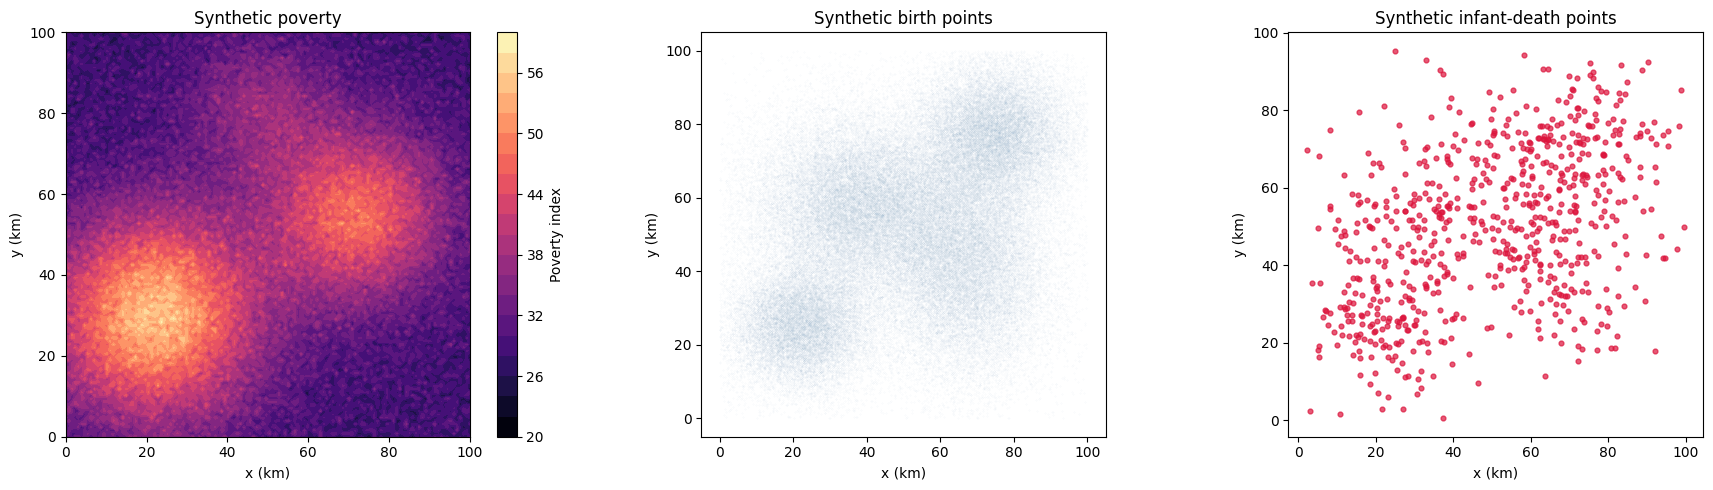

/var/folders/4r/9815q2g56t18df6kvlcn1mhc0000gn/T/ipykernel_43952/2881218141.py:87: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


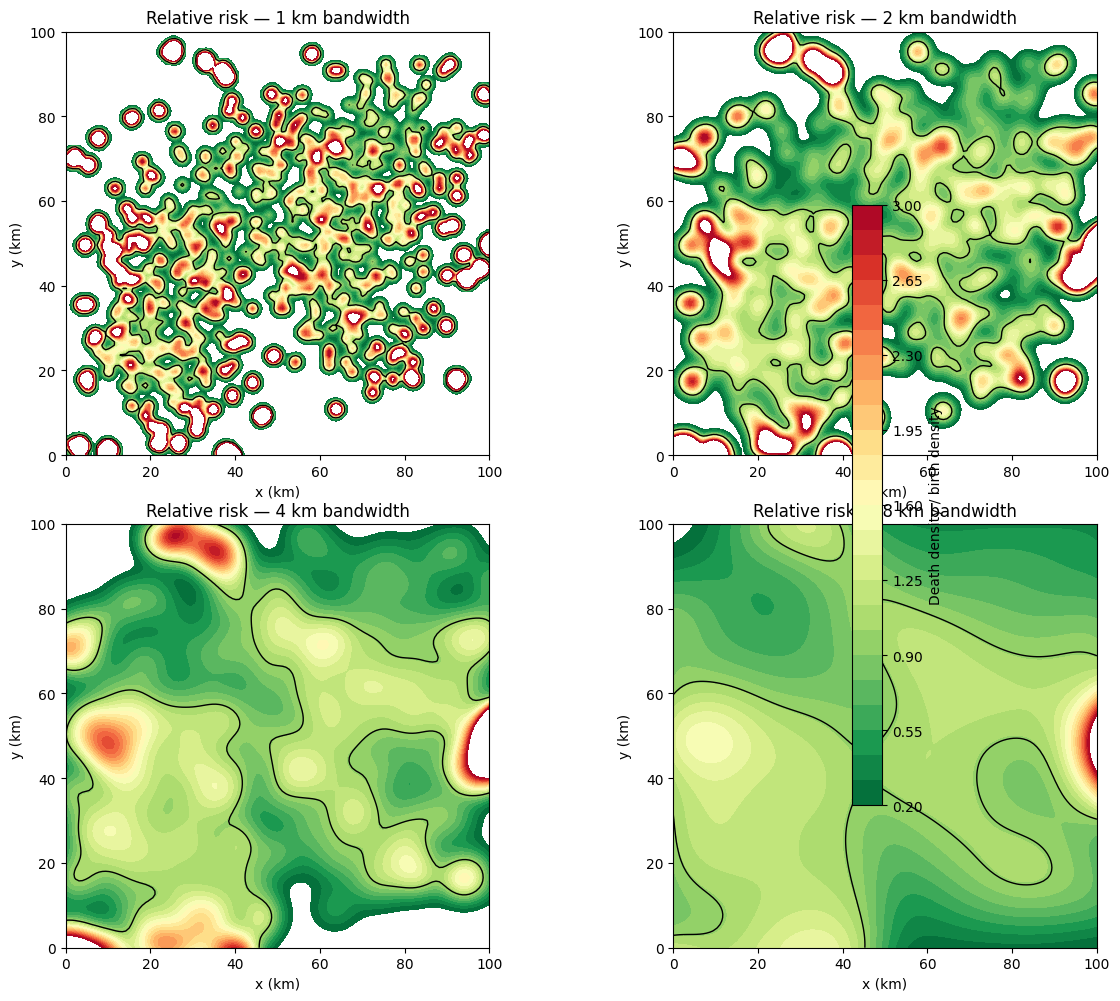

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

rng = np.random.default_rng(563)
xgrid = np.linspace(0, 100, 128)
ygrid = np.linspace(0, 100, 128)
xx, yy = np.meshgrid(xgrid, ygrid)

# Synthetic continuous poverty surface
poverty = (
    28
    + 26*np.exp(-((xx-22)**2+(yy-30)**2)/(2*18**2))
    + 19*np.exp(-((xx-72)**2+(yy-55)**2)/(2*15**2))
    + 8*np.exp(-((xx-48)**2+(yy-82)**2)/(2*12**2))
)
poverty = np.clip(poverty + rng.normal(0, 2, poverty.shape), 5, 65)

# 94,373 fake birth locations
birth_count = 94373
birth_clusters = [(38,58,15,13,0.33), (67,42,12,16,0.27),
                  (22,25,10,9,0.18), (75,78,11,10,0.22)]
birth_parts = []
remaining = birth_count
for i, (cx,cy,sx,sy,proportion) in enumerate(birth_clusters):
    n = remaining if i == len(birth_clusters)-1 else int(round(birth_count*proportion))
    remaining -= n
    birth_parts.append(rng.normal((cx,cy), (sx,sy), size=(n,2)))
birth_points = np.vstack(birth_parts)
birth_points = birth_points[(birth_points[:,0]>=0)&(birth_points[:,0]<=100)&
                            (birth_points[:,1]>=0)&(birth_points[:,1]<=100)]
if len(birth_points)<birth_count:
    deficit=birth_count-len(birth_points)
    birth_points=np.vstack([birth_points,rng.uniform((0,0),(100,100),size=(deficit,2))])

# Poverty-dependent fake infant deaths
from scipy.interpolate import RegularGridInterpolator
poverty_interp = RegularGridInterpolator((ygrid,xgrid), poverty,
                                         bounds_error=False, fill_value=None)
birth_poverty = poverty_interp(birth_points[:,[1,0]])
low, high = birth_poverty.min(), birth_poverty.max()
probability = 0.45 + 1.55*(birth_poverty-low)/(high-low)
probability /= probability.sum()
death_indices = rng.choice(len(birth_points), size=705, replace=False, p=probability)
death_points = birth_points[death_indices]

# Map KDE functions on the linked lesson's 128 x 128 grid.
dx=xgrid[1]-xgrid[0]; dy=ygrid[1]-ygrid[0]
x_edges=np.r_[xgrid[0]-dx/2,xgrid[:-1]+dx/2,xgrid[-1]+dx/2]
y_edges=np.r_[ygrid[0]-dy/2,ygrid[:-1]+dy/2,ygrid[-1]+dy/2]

def kde(points, bandwidth_km, density=False):
    hist,_,_=np.histogram2d(points[:,1],points[:,0],bins=[y_edges,x_edges])
    smoothed=gaussian_filter(hist,sigma=(bandwidth_km/dy,bandwidth_km/dx),mode='nearest')
    return smoothed/(smoothed.sum()*dx*dy) if density else smoothed/(dx*dy)

bandwidths=[1.0,2.0,4.0,8.0]
birth_density={h:kde(birth_points,h,density=True) for h in bandwidths}
death_density={h:kde(death_points,h,density=True) for h in bandwidths}
relative_risk={h:np.divide(death_density[h],birth_density[h],
                           out=np.zeros_like(death_density[h]),
                           where=birth_density[h]>1e-12)
               for h in bandwidths}

print('Synthetic birth points:',len(birth_points))
print('Synthetic infant-death points:',len(death_points))

# Poverty and event maps
fig,axes=plt.subplots(1,3,figsize=(18,5))
poverty_im=axes[0].contourf(xx,yy,poverty,levels=20,cmap='magma')
axes[0].set(title='Synthetic poverty',xlabel='x (km)',ylabel='y (km)',aspect='equal')
fig.colorbar(poverty_im,ax=axes[0],label='Poverty index')
axes[1].scatter(birth_points[:,0],birth_points[:,1],s=.05,alpha=.07,color='steelblue')
axes[1].set(title='Synthetic birth points',xlabel='x (km)',ylabel='y (km)',aspect='equal')
axes[2].scatter(death_points[:,0],death_points[:,1],s=12,alpha=.7,color='crimson')
axes[2].set(title='Synthetic infant-death points',xlabel='x (km)',ylabel='y (km)',aspect='equal')
plt.tight_layout(); plt.show()

# Four fixed-bandwidth relative-risk maps
fig,axes=plt.subplots(2,2,figsize=(12,10))
for ax,h in zip(axes.ravel(),bandwidths):
    values=relative_risk[h]
    im=ax.contourf(xx,yy,values,levels=np.linspace(.2,3,25),cmap='RdYlGn_r',vmin=.2,vmax=3)
    ax.contour(xx,yy,values,levels=[1],colors='black',linewidths=1)
    ax.set(title=f'Relative risk — {h:.0f} km bandwidth',xlabel='x (km)',ylabel='y (km)',aspect='equal')
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.78,label='Death density / birth density')
plt.tight_layout(); plt.show()


### Conceptual questions

1. Why are live births used as the denominator for infant mortality?
2. How is a 128 × 128 grid used to make the KDE maps spatially continuous?
3. Compare 1 km and 8 km bandwidths. Which map preserves local features?
4. Why can a map of total deaths differ from a map of relative infant mortality?
5. Poverty is simulated as a covariate rather than as the population at risk. What extra data would be required for a real study?


### Conceptual questions — Suggested answers

1. **Why births as denominator?**
   Infant mortality is a risk among babies who were born alive, so live births define the population *at risk*. Using total population would dilute the rate and make areas with different age structures less comparable.

2. **How does the 128 × 128 grid create continuous KDE maps?**
   The study region is split into 128 × 128 small cells. KDE estimates event intensity at each cell center by smoothing nearby points with a kernel and bandwidth. Interpolating these cell estimates yields a continuous-looking surface for births, deaths, and relative risk.

3. **1 km vs 8 km bandwidth: which preserves local features?**
   A **1 km** bandwidth preserves fine-scale hotspots and local variation (higher detail, noisier surface). An **8 km** bandwidth strongly smooths the map (lower noise, but local structure can be blurred). So 1 km preserves local features better.

4. **Why can total-death maps differ from relative-risk maps?**
   Total deaths are influenced by where many births occur (population concentration). Relative risk compares death intensity to birth intensity, so an area with many deaths may still have average risk if births are also very high, and a low-count area can show elevated risk if births are very low.

5. **What extra data are needed for a real poverty-risk study?**
   You would need geocoded or area-linked **real** records for births and infant deaths (with dates), reliable poverty indicators at compatible spatial scale (e.g., census tract), and supporting confounders (maternal age, access to care, urban/rural status, education, etc.). Also needed: data-quality checks, harmonized boundaries, and ethics/privacy safeguards for sensitive health data.

### Guided activities

- Change the bandwidth list and observe changes in the relative-risk contours.
- Move a poverty hotspot and compare the new distribution of synthetic infant deaths.
- Replace the Gaussian kernel with a larger or smaller kernel and discuss edge effects.
- Extract the relative-risk value at 20 synthetic locations and compare it with local poverty.

> These maps use fake data for teaching. They do not describe actual place-based health outcomes.


## **Part D — Computational Problems**

Students will **work in pairs** to develop, implement, and analyze their solutions. The completed work will be submitted as part of the course exercise sheets.

Choose one of the computational-physics problems below. Your submission should include the code, a clear description of the numerical method, relevant plots or diagnostics, and a short interpretation of the results. Explain why the selected model and parameters are appropriate, and identify at least one limitation of your approach.


### **Problem 1 — Normal (undamped) oscillator**

An ideal undamped oscillator has the form

$$
y(t)=A\sin(\omega t)+B\cos(\omega t)+C,
$$

where $A$ and $B$ determine the amplitude and phase. The measured amplitude and phase are

$$
R=\sqrt{A^2+B^2},
\qquad
\phi=\operatorname{atan2}(B,A).
$$

The model is linear in $A$, $B$, and $C$ when the angular frequency $\omega$ is known.

#### Level 1 — Guided implementation

Generate noisy data from

$$
y(t)=R\sin(\omega t+\phi)+C,
$$

with $R=3.5$, $\omega=1.2\ \mathrm{rad/s}$, $\phi=0.4\ \mathrm{rad}$, and $C=1.2$. Then:

1. construct the design matrix $X=[\sin(\omega t),\cos(\omega t),1]$;
2. fit $A$, $B$, and $C$ with `np.linalg.lstsq`;
3. recover $R$ and $\phi$;
4. plot the noisy data and fitted curve.

#### Level 2 — Numerical investigation

Repeat the guided fit for several noise levels, for example $\sigma=0.05$, $0.2$, and $0.5$.

Compare:

- fitted amplitude error;
- fitted phase error;
- residual standard deviation;
- the condition number of the design matrix.

Interpret how noise affects the recovered oscillator parameters.

#### Level 3 — Statistical analysis

For 500 independent trials, generate the same oscillator with random noise at fixed $\sigma$.

Use least squares in each trial and estimate:

- mean and standard deviation of $R$;
- mean and standard deviation of $\phi$;
- bias in amplitude and phase;
- the empirical 95% interval for both parameters.

Explain why the amplitude estimate is not perfectly unbiased at finite noise and discuss the difference between least-squares uncertainty and experimental uncertainty.


Normal oscillator — Level 1 answer
True parameters: R=3.500, omega=1.200, phi=0.400, C=1.200
Fitted parameters: R=3.494, omega=1.200, phi=0.398, C=1.214
Amplitude error: -0.006
Phase error: -0.002 rad
Residual standard deviation: 0.191


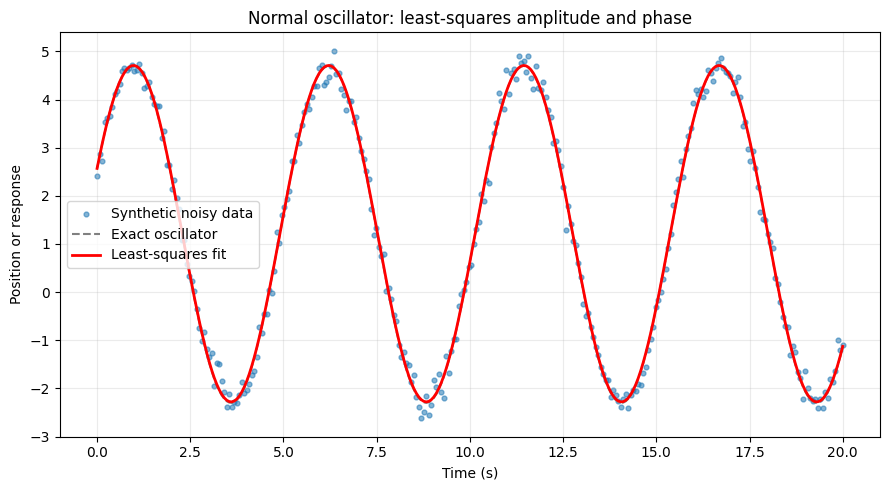

Normal oscillator — Level 2
sigma | amplitude error | phase error | residual sigma
0.05 | -0.007 | +0.000 | 0.052
0.20 | +0.022 | -0.005 | 0.199
0.50 | -0.028 | +0.020 | 0.456
Design-matrix condition number: 1.448
Normal oscillator — Level 3
Amplitude mean=3.500, std=0.015, bias=-0.000
Amplitude 95% interval=[3.473, 3.528]
Phase mean=0.400, std=0.004, bias=-0.000 rad
Phase 95% interval=[0.392, 0.408] rad


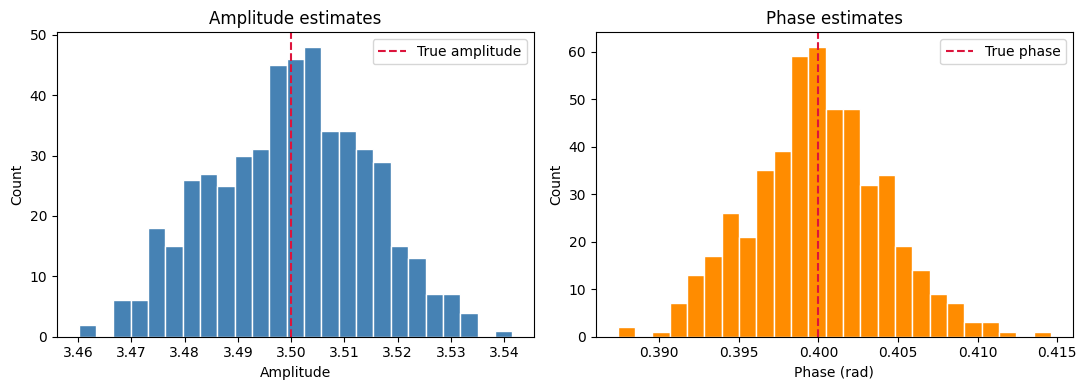

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# Synthetic normal-oscillator data
rng_normal = np.random.default_rng(2026)
omega_normal = 1.2
R_true = 3.5
phi_true = 0.4
C_true = 1.2
noise_true = 0.18

t_normal = np.linspace(0, 20, 300)
y_true_normal = R_true*np.sin(omega_normal*t_normal + phi_true) + C_true
y_normal = y_true_normal + rng_normal.normal(0, noise_true, t_normal.size)

X_normal = np.column_stack([
    np.sin(omega_normal*t_normal),
    np.cos(omega_normal*t_normal),
    np.ones_like(t_normal),
])

A_normal, B_normal, C_normal = np.linalg.lstsq(X_normal, y_normal, rcond=None)[0]
R_normal = np.hypot(A_normal, B_normal)
phi_normal = np.arctan2(B_normal, A_normal)
y_fit_normal = A_normal*np.sin(omega_normal*t_normal) + B_normal*np.cos(omega_normal*t_normal) + C_normal

print('Normal oscillator — Level 1 answer')
print(f'True parameters: R={R_true:.3f}, omega={omega_normal:.3f}, phi={phi_true:.3f}, C={C_true:.3f}')
print(f'Fitted parameters: R={R_normal:.3f}, omega={omega_normal:.3f}, phi={phi_normal:.3f}, C={C_normal:.3f}')
print(f'Amplitude error: {R_normal-R_true:+.3f}')
print(f'Phase error: {phi_normal-phi_true:+.3f} rad')
print(f'Residual standard deviation: {np.std(y_normal-y_fit_normal):.3f}')

plt.figure(figsize=(9,5))
plt.scatter(t_normal, y_normal, s=12, alpha=.55, label='Synthetic noisy data')
plt.plot(t_normal, y_true_normal, '--', color='gray', label='Exact oscillator')
plt.plot(t_normal, y_fit_normal, 'r-', linewidth=2, label='Least-squares fit')
plt.xlabel('Time (s)'); plt.ylabel('Position or response')
plt.title('Normal oscillator: least-squares amplitude and phase')
plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

# Level 2 — fit at different noise levels
noise_levels = [0.05, 0.2, 0.5]
normal_noise_results = []
for sigma in noise_levels:
    noisy = y_true_normal + rng_normal.normal(0, sigma, t_normal.size)
    coeffs = np.linalg.lstsq(X_normal, noisy, rcond=None)[0]
    fitted_R = np.hypot(coeffs[0], coeffs[1])
    fitted_phi = np.arctan2(coeffs[1], coeffs[0])
    residual = noisy-(coeffs[0]*np.sin(omega_normal*t_normal)+coeffs[1]*np.cos(omega_normal*t_normal)+coeffs[2])
    normal_noise_results.append((sigma, fitted_R-R_true, fitted_phi-phi_true, np.std(residual)))

print('Normal oscillator — Level 2')
print('sigma | amplitude error | phase error | residual sigma')
for row in normal_noise_results:
    print(f'{row[0]:.2f} | {row[1]:+.3f} | {row[2]:+.3f} | {row[3]:.3f}')
print(f'Design-matrix condition number: {np.linalg.cond(X_normal):.3f}')

# Level 3 — Monte Carlo uncertainty
n_trials_normal = 500
R_trials = np.empty(n_trials_normal)
phi_trials = np.empty(n_trials_normal)
for trial in range(n_trials_normal):
    trial_y = y_true_normal + rng_normal.normal(0, noise_true, t_normal.size)
    coeffs = np.linalg.lstsq(X_normal, trial_y, rcond=None)[0]
    R_trials[trial] = np.hypot(coeffs[0], coeffs[1])
    phi_trials[trial] = np.arctan2(coeffs[1], coeffs[0])

print('Normal oscillator — Level 3')
print(f'Amplitude mean={R_trials.mean():.3f}, std={R_trials.std(ddof=1):.3f}, bias={R_trials.mean()-R_true:+.3f}')
print(f'Amplitude 95% interval=[{np.percentile(R_trials,2.5):.3f}, {np.percentile(R_trials,97.5):.3f}]')
print(f'Phase mean={phi_trials.mean():.3f}, std={phi_trials.std(ddof=1):.3f}, bias={phi_trials.mean()-phi_true:+.3f} rad')
print(f'Phase 95% interval=[{np.percentile(phi_trials,2.5):.3f}, {np.percentile(phi_trials,97.5):.3f}] rad')

fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].hist(R_trials,bins=25,color='steelblue',edgecolor='white')
axes[0].axvline(R_true,color='crimson',linestyle='--',label='True amplitude')
axes[0].set(title='Amplitude estimates',xlabel='Amplitude',ylabel='Count'); axes[0].legend()
axes[1].hist(phi_trials,bins=25,color='darkorange',edgecolor='white')
axes[1].axvline(phi_true,color='crimson',linestyle='--',label='True phase')
axes[1].set(title='Phase estimates',xlabel='Phase (rad)',ylabel='Count'); axes[1].legend()
plt.tight_layout(); plt.show()


#### **Answer — Normal oscillator**

The fitted coefficients satisfy

$$
y(t)=A\sin(\omega t)+B\cos(\omega t)+C.
$$

To compare with the target oscillator, convert to

$$
R=\sqrt{A^2+B^2},
\qquad
\phi=\operatorname{atan2}(B,A).
$$

For a generated data set with the stated parameters, the answer should be close to

- $R=3.5$;
- $\omega=1.2\ \mathrm{rad/s}$;
- $\phi=0.4\ \mathrm{rad}$;
- $C=1.2$.

Small differences are expected because of the added noise. The Monte Carlo section estimates the distribution of the recovered parameters. The amplitude $R$ is obtained from a square root of squared fitted coefficients, so it can have a small positive finite-sample bias when noise is large. The phase is usually reported on $[-\pi,\pi]$ and should be compared with the true phase using circular or wrapped differences if repeated trials cross a branch boundary.


### **Problem 2 — Damped oscillator**

We improve the damped-oscillator exercise using the course reference solution's workflow:

1. Identify the nonlinear model.
2. Make a reasonable initial guess.
3. Fit all parameters with nonlinear least squares.
4. Estimate covariance-based uncertainty and Monte Carlo uncertainty.
5. Check residuals and parameter identifiability.

The model is

$$
y(t)=Ae^{-\gamma t}\cos(\omega t+\phi)+C.
$$

#### Level 1 — Guided nonlinear fit

Generate synthetic data with $A=4.0$, $\gamma=0.12$, $\omega=1.5\ \mathrm{rad/s}$, $\phi=0.30\ \mathrm{rad}$, and $C=0.20$. Fit with `scipy.optimize.curve_fit` using the initial guess $(3.5,0.10,1.5,0.20,0.10)$.

Report the fitted parameters, covariance uncertainties, RMS residual, data-versus-fit plot, residual-versus-time plot, and residual distribution.

#### Level 2 — Numerical investigation

Estimate an initial angular frequency from the FFT after removing the mean. Refine it by nonlinear fitting. Repeat the fit for noise levels $\sigma=0.05$, $0.15$, and $0.35$.

Compare fitted $A$, $\gamma$, $\omega$, $\phi$, and $C$; covariance uncertainty; RMS residual; sensitivity to initial guesses; and the FFT estimate.

#### Level 3 — Statistical analysis

Run 300 independent synthetic trials. In each trial, generate noisy data and fit all five parameters. Store the results and compute bias, Monte Carlo standard deviations, covariance-derived uncertainties, and 95% intervals.

Discuss correlations among $A$, $\gamma$, $\omega$, and $\phi$, parameter identifiability, and the difference between covariance and empirical Monte Carlo uncertainty.


#### **Answer — Damped oscillator**

The complete nonlinear model is

$$
y(t)=Ae^{-\gamma t}\cos(\omega t+\phi)+C.
$$

The fit should recover values close to $A=4.0$, $\gamma=0.12$, $\omega=1.5\ \mathrm{rad/s}$, $\phi=0.30\ \mathrm{rad}$, and $C=0.20$. The RMS residual should be close to the noise scale.

The FFT gives a useful initial frequency estimate, but nonlinear least squares should refine all parameters together. Covariance uncertainty describes local parameter curvature, while Monte Carlo uncertainty describes repeated experiments. Parameter correlations reveal identifiability issues, especially between frequency and phase and between amplitude and damping.


## **Summary**

- **Kernel density estimation** places a kernel over every event location and sums the kernels to create a continuous intensity or density surface.
- Small KDE bandwidths preserve local structure but may be noisy. Large bandwidths reduce noise but can hide important hotspots.
- Separate KDE surfaces can represent births and infant deaths. The death-density-to-birth-density ratio is a spatial relative-risk surface.


- **Interpolation** constructs a function that passes through every trusted data point. A single high-degree polynomial can show Runge's phenomenon near the edges.
- **Curve fitting** estimates a physically motivated model without requiring every noisy observation to lie exactly on the fitted curve.

- A **normal oscillator** can be fitted with $A\sin(\omega t)+B\cos(\omega t)+C$ when $\omega$ is known. Amplitude and phase come from $A$ and $B$.
- A **damped oscillator** requires fitting amplitude, damping, frequency, phase, and offset together. Residual plots and covariance or Monte Carlo uncertainty provide fit diagnostics.

The choice of nodes, bandwidth, study window, and model parameters affects the final surface. These choices should be justified by data, scale, and the scientific question.